# Fase 3: Modelado predictivo del rendimiento académico
Notebook independiente para predecir `grades` mediante regresión.

## 1. Objetivo y alcance
Se estima `grades` (escala 0–100) a partir de cinco variables observadas. La selección final se revisa mediante una comparación reproducible entre la combinación heredada de Fase 2 (`uso_no_gaming`), la alternativa usada inicialmente en Fase 3 (`social_activity`) y una combinación con ambos predictores. No se utilizan `grades_original`, banderas de limpieza ni categorías derivadas del objetivo.

## 2. Correcciones consideradas
Se conserva el dataset limpio validado en fases anteriores. La versión anterior de este notebook reemplazaba `uso_no_gaming` por `social_activity` sin documentar una comparación sistemática. Esta rama corrige esa trazabilidad: ambas alternativas y su combinación se comparan usando únicamente entrenamiento y validación cruzada. No se afirma que `social_activity` fuera superior sin evidencia.

## 3. Configuración reproducible

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import KFold, train_test_split
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src.fase3_model import FEATURES, TARGET, RANDOM_STATE, compare_feature_sets, cross_validate_models, evaluate_fitted_models, save_bundle, tune_models

DATA_PATH = ROOT / 'data' / 'processed' / 'gaming_academic_clean.csv'
OUTPUT = ROOT / 'output' / 'fase3'
OUTPUT.mkdir(exist_ok=True)
pd.set_option('display.max_columns', None)

## 4. Carga y auditoría del dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Dimensiones: {df.shape}')
display(df.head())
display(df[FEATURES + [TARGET]].describe().T)
assert df[FEATURES + [TARGET]].notna().all().all()

Dimensiones: (8000, 15)


,age,gender,gaming_hours,study_hours,sleep_hours,attendance,social_activity,device_usage,uso_no_gaming,stress_level,gaming_cat,grades,grades_original,flag_grades_gt100,flag_ajustado
0,22,Male,7.23,8.78,6.96,91.44,3.25,9.36,2.13,Low,Alto,86.46,86.459555,False,True
1,19,Male,0.07,8.72,7.63,63.63,1.02,3.21,3.14,Medium,Bajo,98.23,98.230000,False,False
2,23,Female,1.73,9.56,4.40,83.26,3.46,5.56,3.83,High,Bajo,90.56,90.560000,False,False
3,20,Female,6.62,1.68,7.83,75.04,1.46,11.78,5.16,Low,Alto,32.67,32.670000,False,False
4,22,Female,5.36,5.83,5.55,65.57,1.01,8.23,2.87,Low,Medio,58.71,58.710000,False,False


,count,mean,std,min,25%,50%,75%,max
gaming_hours,8000.0,4.076562,2.297137,0.0,2.13,4.130,6.0400,8.00
study_hours,8000.0,5.448730,2.559515,1.0,3.24,5.460,7.6400,10.00
sleep_hours,8000.0,6.482910,1.431871,4.0,5.24,6.500,7.6900,9.00
attendance,8000.0,79.886525,11.580419,60.0,69.78,79.695,90.1000,100.00
uso_no_gaming,8000.0,3.509753,1.439222,1.0,2.27,3.530,4.7600,6.66
grades,8000.0,66.080435,22.252701,0.0,49.88,67.070,83.9925,100.00


## 5. Variable objetivo y predictores
La selección es previa al entrenamiento y se limita a variables disponibles antes de conocer la calificación.

In [3]:
print('Objetivo:', TARGET)
print('Predictores:', FEATURES)
display(df[TARGET].describe())

Objetivo: grades
Predictores: ['gaming_hours', 'study_hours', 'sleep_hours', 'attendance', 'uso_no_gaming']


count    8000.000000
mean       66.080435
std        22.252701
min         0.000000
25%        49.880000
50%        67.070000
75%        83.992500
max       100.000000
Name: grades, dtype: float64

## 6. Partición entrenamiento/prueba
Se reserva 20% para una evaluación final no usada durante la selección.

In [4]:
X = df[FEATURES].copy()
y = df[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(6400, 5) (1600, 5)


## 7. Comparación de predictores
La documentación de Fase 2 utilizaba `uso_no_gaming`, mientras que la versión inicial de Fase 3 utilizaba `social_activity`. Para corregir la inconsistencia, se comparan tres conjuntos bajo los mismos folds: Fase 2, Fase 3 y ambos predictores. La prueba final permanece intacta hasta la evaluación del modelo seleccionado.

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_df = df.loc[X_train.index].copy()
feature_set_results = compare_feature_sets(train_df, y_train, cv)
feature_set_results.to_csv(OUTPUT / 'fase3_comparacion_predictores.csv', index=False)
best_feature_set = feature_set_results.iloc[0]['Conjunto de predictores']
display(feature_set_results)
print('Mejor combinación y modelo por RMSE CV:', best_feature_set, feature_set_results.iloc[0]['Modelo'])

,Conjunto de predictores,Modelo,RMSE CV,MAE CV,R2 CV
0,Fase 2 + uso_no_gaming,Random Forest,5.805849,4.562213,0.931983
1,Fase 3 + social_activity,Random Forest,5.818674,4.572827,0.931679
2,Ambos complementarios,Random Forest,5.826576,4.582819,0.931493
3,Fase 2 + uso_no_gaming,KNN,6.601217,5.167533,0.912116
4,Fase 3 + social_activity,KNN,6.641268,5.212673,0.911013
5,Fase 2 + uso_no_gaming,Linear Regression,6.644701,5.282622,0.910956
6,Fase 3 + social_activity,Linear Regression,6.644757,5.282868,0.910955
7,Ambos complementarios,Linear Regression,6.645042,5.283047,0.910947
8,Ambos complementarios,KNN,7.051242,5.522312,0.899721
9,Fase 2 + uso_no_gaming,DummyRegressor,22.273858,18.592422,-0.000433


Mejor combinación y modelo por RMSE CV: Fase 2 + uso_no_gaming Random Forest


## 8. Línea base
La línea base predice siempre la media del entrenamiento.

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = cross_validate_models(X_train, y_train, cv)
display(cv_results)

,Modelo,RMSE CV,MAE CV,R2 CV,RMSE CV std
0,Random Forest,5.805849,4.562213,0.931983,0.070090
1,KNN,6.601217,5.167533,0.912116,0.084441
2,Linear Regression,6.644701,5.282622,0.910956,0.032586
3,DummyRegressor,22.273858,18.592422,-0.000433,0.196348


## 9. Tres familias de modelos
Se comparan regresión lineal, Random Forest y KNN bajo los mismos folds. Los modelos sensibles a escala incorporan `StandardScaler` dentro de un pipeline.

## 10. Validación cruzada

In [7]:
display(cv_results.style.format({'RMSE CV':'{:.3f}','MAE CV':'{:.3f}','R2 CV':'{:.3f}','RMSE CV std':'{:.3f}'}))

,Modelo,RMSE CV,MAE CV,R2 CV,RMSE CV std
0,Random Forest,5.806,4.562,0.932,0.070
1,KNN,6.601,5.168,0.912,0.084
2,Linear Regression,6.645,5.283,0.911,0.033
3,DummyRegressor,22.274,18.592,-0.000,0.196


## 11. Optimización de hiperparámetros
GridSearchCV optimiza RMSE usando únicamente el conjunto de entrenamiento y los mismos cinco folds.

In [8]:
fitted, tuning_results = tune_models(X_train, y_train, cv)
display(tuning_results)

,Modelo,RMSE CV optimizado,Mejores parámetros
0,Linear Regression,NaN,{}
1,Random Forest,5.766062,"{'max_depth': 20, 'min_samples_leaf': 3, 'n_es..."
2,KNN,6.183874,"{'model__n_neighbors': 21, 'model__p': 1, 'mod..."


## 12. Evaluación en prueba
Estas métricas se calculan una sola vez sobre el conjunto reservado. MAPE se interpreta con cautela porque `grades` puede ser cero.

In [9]:
test_results, predictions = evaluate_fitted_models(fitted, X_test, y_test)
display(test_results.style.format({'RMSE':'{:.3f}','MAE':'{:.3f}','MAPE (%)':'{:.3f}','R2':'{:.3f}'}))
test_results.to_csv(OUTPUT / 'fase3_resultados_prueba.csv', index=False)

,Modelo,RMSE,MAE,MAPE (%),R2
0,Random Forest,6.001,4.609,8.964,0.927
1,KNN,6.333,4.972,10.051,0.918
2,Linear Regression,6.984,5.541,10.559,0.901


## 13. Brecha de generalización
La diferencia entre RMSE de validación y prueba ayuda a discutir sobreajuste, no solo el ranking.

In [10]:
comparison = cv_results[['Modelo','RMSE CV']].merge(test_results[['Modelo','RMSE']], on='Modelo')
comparison['Brecha RMSE'] = comparison['RMSE'] - comparison['RMSE CV']
display(comparison.sort_values('RMSE'))

,Modelo,RMSE CV,RMSE,Brecha RMSE
0,Random Forest,5.805849,6.001218,0.195369
1,KNN,6.601217,6.333482,-0.267735
2,Linear Regression,6.644701,6.983956,0.339256


## 14. Diagnóstico de residuos y peores predicciones

,gaming_hours,study_hours,sleep_hours,attendance,uso_no_gaming,grades_real,grades_predicted,residuo,error_abs
3592,0.36,1.17,4.31,86.02,1.50,27.32,52.273946,-24.953946,24.953946
2718,1.87,5.24,4.96,93.71,2.23,59.58,84.170630,-24.590630,24.590630
877,4.26,3.78,5.83,99.41,4.24,80.55,57.191279,23.358721,23.358721
1515,5.87,2.70,4.85,97.94,3.40,59.05,36.974920,22.075080,22.075080
6803,3.51,4.09,6.71,72.31,3.06,82.55,60.630029,21.919971,21.919971
7641,6.38,6.12,4.84,97.62,5.53,71.98,50.512003,21.467997,21.467997
6931,3.43,3.95,6.68,68.32,2.26,77.59,59.318471,18.271529,18.271529
2948,0.66,5.14,5.06,98.16,3.76,67.09,84.847690,-17.757690,17.757690
5436,7.25,8.01,5.01,68.52,5.59,73.19,55.767862,17.422138,17.422138
4466,2.78,5.79,6.44,68.38,3.84,88.55,71.156225,17.393775,17.393775


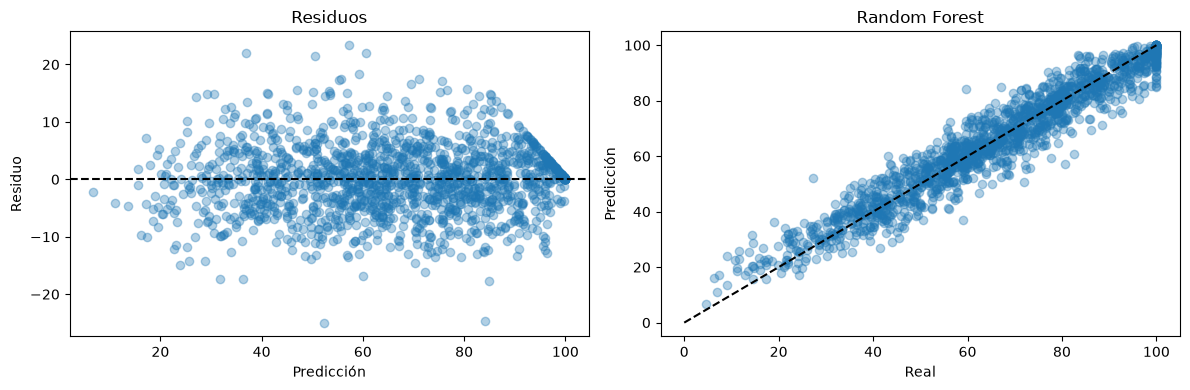

In [11]:
winner_name = test_results.iloc[0]['Modelo']
winner_pred = predictions[winner_name]
errors = X_test.copy()
errors['grades_real'] = y_test.to_numpy()
errors['grades_predicted'] = winner_pred
errors['residuo'] = errors['grades_real'] - errors['grades_predicted']
errors['error_abs'] = errors['residuo'].abs()
display(errors.nlargest(10, 'error_abs'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(errors['grades_predicted'], errors['residuo'], alpha=.35)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(xlabel='Predicción', ylabel='Residuo', title='Residuos')
axes[1].scatter(errors['grades_real'], errors['grades_predicted'], alpha=.35)
axes[1].plot([0,100], [0,100], linestyle='--', color='black')
axes[1].set(xlabel='Real', ylabel='Predicción', title=winner_name)
plt.tight_layout()
plt.savefig(OUTPUT / 'fase3_diagnostico_residuos.png', dpi=150)
plt.show()

## 15. Interpretación de variables
Para comparar importancia entre familias se usa permutación sobre la prueba. Es una medida de asociación predictiva, no causalidad.

La comparación de conjuntos se realizó antes de tocar la prueba y favoreció la combinación heredada de Fase 2 con `uso_no_gaming`, por una diferencia pequeña frente a `social_activity` y frente a ambos predictores. Con el conjunto seleccionado, el modelo ganador se interpreta usando importancia por permutación: `study_hours` y `gaming_hours` son los predictores principales, seguidos de `sleep_hours`, `attendance` y `uso_no_gaming`.

Estos resultados indican utilidad predictiva relativa dentro de este dataset, pero no demuestran causalidad. En particular, no es correcto concluir que estudiar más cause mejores calificaciones ni que jugar más cause un menor rendimiento. La comparación no demuestra que `social_activity` sea mejor que `uso_no_gaming`; de hecho, las diferencias observadas son pequeñas y deben interpretarse como evidencia predictiva específica de esta muestra.

La evidencia debe interpretarse como exploratoria: el dataset es observacional y simulado, puede contener relaciones entre predictores y no representa todos los factores que influyen en el rendimiento académico. Por ello, el modelo no debe utilizarse para etiquetar o sancionar estudiantes, y cualquier aplicación externa requiere validación con una población independiente.

In [12]:
winner = fitted[winner_name]
importance = permutation_importance(winner, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring='neg_root_mean_squared_error', n_jobs=1)
importance_df = pd.DataFrame({'Variable': FEATURES, 'Importancia media': importance.importances_mean, 'Desv. estándar': importance.importances_std}).sort_values('Importancia media', ascending=False)
display(importance_df)
importance_df.to_csv(OUTPUT / 'fase3_importancia_variables.csv', index=False)

,Variable,Importancia media,Desv. estándar
1,study_hours,17.982862,0.251804
0,gaming_hours,12.743851,0.345844
2,sleep_hours,3.697473,0.091444
3,attendance,1.370743,0.064109
4,uso_no_gaming,0.016091,0.010996


## 16. Selección y exportación del ganador

In [13]:
print('Modelo ganador en prueba:', winner_name)
save_bundle(winner, OUTPUT / 'fase3_modelo_ganador.joblib')
print('Modelo guardado.')

Modelo ganador en prueba: Random Forest
Modelo guardado.


## 17. Limitaciones, ética y uso responsable
El dataset es observacional y simulado según la documentación previa; las métricas no prueban efectos causales. La predicción no debe usarse para etiquetar o sancionar estudiantes. La calidad puede variar fuera del rango observado, por lo que toda inferencia nueva debe validar unidades, rangos y contexto.

## 18. Conclusión
La conclusión final debe reportar el ganador real, sus métricas de validación y prueba, la brecha de generalización, los errores extremos y las variables importantes. No se decide el ganador antes de ejecutar el experimento.

In [14]:
print(f'Resumen: {winner_name} | RMSE={test_results.iloc[0].RMSE:.3f} | MAE={test_results.iloc[0].MAE:.3f} | R2={test_results.iloc[0].R2:.3f}')

Resumen: Random Forest | RMSE=6.001 | MAE=4.609 | R2=0.927
